# Étude 2 — Analyse exploratoire : faillites d'entreprises (fort déséquilibre)

Données : *Polish Companies Bankruptcy* (UCI, Tomczak 2016, CC BY 4.0), fichier de la 3e année : 64 ratios financiers d'une année et faillite dans les 3 ans qui suivent. Pour une banque, la faillite d'une entreprise emprunteuse est l'événement de défaut : c'est un problème de **scoring de crédit des entreprises**.

**Toute l'analyse porte sur le jeu de développement** : le jeu de test a été mis de côté avant (`python -m src.faillites.data`).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from src.faillites.config import FEATURES, LABELS, TARGET, FIG
from src.faillites.data import load_dev
from src.faillites.features import slog
from src.plots import set_style, C_GOOD, C_BAD
set_style()
dev = load_dev(); X, y = dev[FEATURES], dev[TARGET]
print(f'{len(dev)} entreprises, {y.sum()} faillites ({y.mean():.2%}) : 1 faillite pour {(1-y.mean())/y.mean():.0f} entreprises saines')

8332 entreprises, 394 faillites (4.73%) : 1 faillite pour 20 entreprises saines


## 1. Valeurs manquantes

La moitié des entreprises ont au moins un ratio manquant. Comme pour HMEQ, on vérifie si l'absence d'un ratio est liée à la faillite.

Entreprises complètes : 46.2%


,manquant (%),faillites si manquant (%),faillites si renseigné (%)
X37,45.4,4.9,4.6
X21,7.5,16.5,3.8
X27,6.8,22.8,3.4
X60,5.8,7.6,4.6
X45,5.8,7.6,4.5
X54,2.3,6.3,4.7
X28,2.3,6.3,4.7
X53,2.3,6.3,4.7
X64,2.3,6.3,4.7
X24,2.3,0.0,4.8


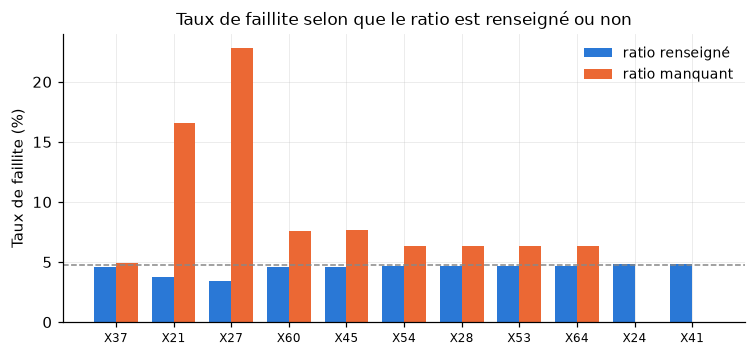

In [2]:
miss = X.isna().mean().sort_values(ascending=False)
print(f"Entreprises complètes : {X.notna().all(axis=1).mean():.1%}")
tab = pd.DataFrame({'manquant (%)': 100*miss, 'faillites si manquant (%)': [100*y[X[c].isna()].mean() if X[c].isna().any() else np.nan for c in miss.index],
                    'faillites si renseigné (%)': [100*y[X[c].notna()].mean() for c in miss.index]})
tab = tab[tab['manquant (%)'] >= 1]; display(tab.round(1))
fig, ax = plt.subplots(figsize=(8, 3.4)); xs = np.arange(len(tab)); w = .38
ax.bar(xs-w/2, tab['faillites si renseigné (%)'], w, color=C_GOOD, label='ratio renseigné')
ax.bar(xs+w/2, tab['faillites si manquant (%)'], w, color=C_BAD, label='ratio manquant')
ax.axhline(100*y.mean(), color='#888', ls='--', lw=1); ax.set_xticks(xs); ax.set_xticklabels(tab.index, fontsize=8)
ax.set_ylabel('Taux de faillite (%)'); ax.set_title('Taux de faillite selon que le ratio est renseigné ou non'); ax.legend()
fig.savefig(FIG/'eda_manquants.png'); plt.show()

## 2. Des distributions à queues extrêmes

Un ratio dont le dénominateur est proche de zéro explose : l'asymétrie est énorme. La transformation logarithmique signée s(x) = signe(x)·log(1+|x|) la ramène à un niveau raisonnable sans changer l'ordre des entreprises.

Asymétrie médiane : 61.2 (brute) -> 1.29 (log signé)
Valeur absolue maximale observée : 11,903,000


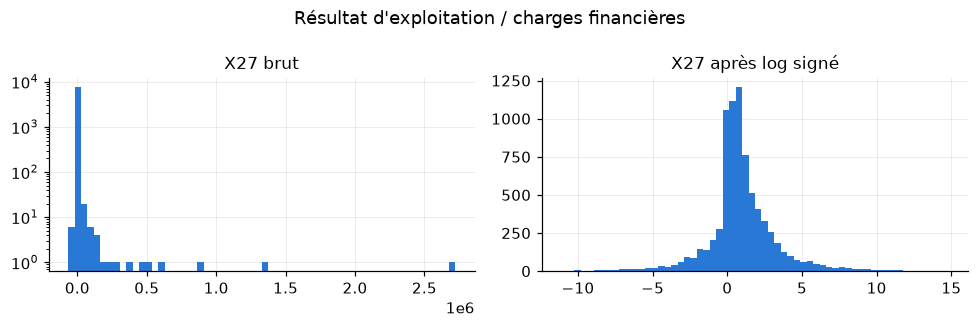

In [3]:
sk = X.skew(); sk2 = slog(X).skew()
print(f'Asymétrie médiane : {sk.abs().median():.1f} (brute) -> {sk2.abs().median():.2f} (log signé)')
print(f'Valeur absolue maximale observée : {np.nanmax(np.abs(X.values)):,.0f}')
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(X['X27'].dropna(), bins=60, color=C_GOOD); axes[0].set_title('X27 brut'); axes[0].set_yscale('log')
axes[1].hist(slog(X['X27'].dropna()), bins=60, color=C_GOOD); axes[1].set_title('X27 après log signé')
fig.suptitle(LABELS['X27']); fig.tight_layout(); fig.savefig(FIG/'eda_asymetrie.png'); plt.show()

## 3. Quels ratios séparent les faillites ?

Statistique de Kolmogorov-Smirnov entre faillites et entreprises saines, ratio par ratio (0 = aucune différence, 1 = séparation parfaite).

,KS,définition
X26,0.364,(Résultat net + amortissements) / total dettes
X16,0.358,(Résultat brut + amortissements) / total dettes
X24,0.353,Résultat brut (sur 3 ans) / total actif
X13,0.326,(Résultat brut + amortissements) / chiffre d'a...
X12,0.324,Résultat brut / dettes à court terme
X23,0.311,Résultat net / chiffre d'affaires
X19,0.299,Résultat brut / chiffre d'affaires
X14,0.297,(Résultat brut + intérêts) / total actif
X18,0.297,Résultat brut / total actif
X7,0.296,EBIT / total actif


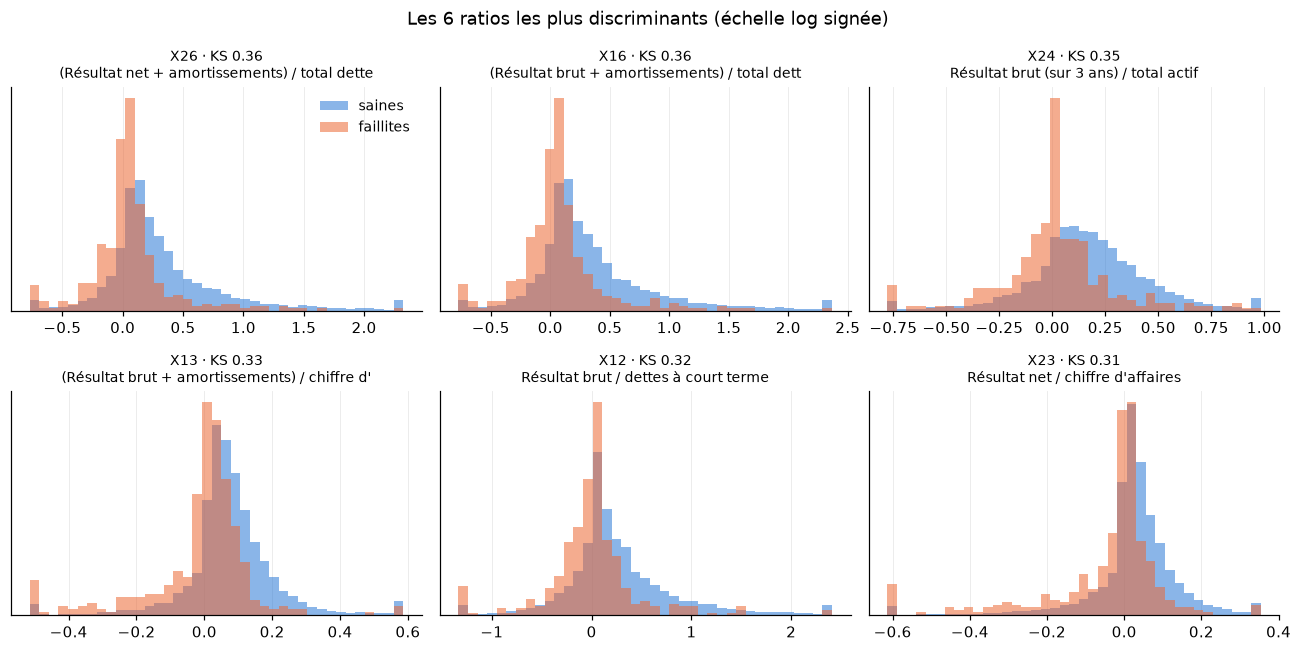

In [4]:
ks = pd.Series({c: ks_2samp(X.loc[y==1, c].dropna(), X.loc[y==0, c].dropna()).statistic for c in FEATURES}).sort_values(ascending=False)
top = ks.head(12)
display(pd.DataFrame({'KS': top.round(3), 'définition': [LABELS[c] for c in top.index]}))
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.ravel(), top.index[:6]):
    v = slog(X[c]); lo, hi = np.nanpercentile(v, [1, 99]); b = np.linspace(lo, hi, 40)
    ax.hist(v[y==0].clip(lo, hi), bins=b, density=True, alpha=.55, color=C_GOOD, label='saines')
    ax.hist(v[y==1].clip(lo, hi), bins=b, density=True, alpha=.55, color=C_BAD, label='faillites')
    ax.set_title(f'{c} · KS {ks[c]:.2f}\n{LABELS[c][:45]}', fontsize=9); ax.set_yticks([])
axes[0,0].legend(); fig.suptitle('Les 6 ratios les plus discriminants (échelle log signée)'); fig.tight_layout()
fig.savefig(FIG/'eda_ratios.png'); plt.show()

## 4. Des ratios très redondants

Plusieurs ratios partagent numérateur ou dénominateur. Un bon générateur doit reproduire cette structure.

Paires de ratios avec |corrélation de Spearman| > 0,9 : 65 sur 2016


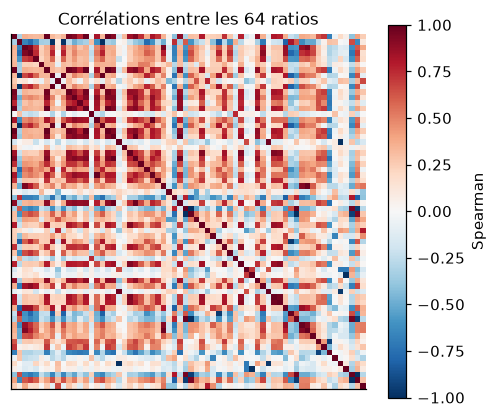

In [5]:
corr = X.corr('spearman'); iu = np.triu_indices(64, 1); a = corr.values[iu]
print(f'Paires de ratios avec |corrélation de Spearman| > 0,9 : {(np.abs(a) > .9).sum()} sur {len(a)}')
fig, ax = plt.subplots(figsize=(5.2, 4.4)); im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); fig.colorbar(im, label='Spearman')
ax.set_title('Corrélations entre les 64 ratios'); fig.savefig(FIG/'eda_correlations.png'); plt.show()

## 5. Ce que l'exploration impose à la suite

| Constat | Conséquence |
|---|---|
| 4,7 % de faillites : 1 pour 20 entreprises saines | PR-AUC comme métrique principale ; doses de 1, 2, 5 et jusqu'à l'équilibre (×20) |
| Seulement environ 315 faillites par pli d'entraînement | Les générateurs apprennent sur très peu d'exemples : le cas où la génération devrait le plus servir |
| Ratios manquants, parfois liés à la faillite | Indicateur « manquant » ; les générateurs reproduisent les valeurs manquantes |
| Asymétrie extrême (valeurs jusqu'à 10^7) | Log signé avant standardisation, et pour les générateurs |
| Ratios fortement corrélés entre eux | La préservation des corrélations est un critère de qualité |

Toutes ces statistiques sont calculées sur le jeu de développement.